<a href="https://colab.research.google.com/github/Shaxkii/oss_261104_practice4/blob/main/oss261104_mission.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip -q install tensorflow-datasets gradio importlib-resources

Loading EMNIST Letters dataset...


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

... (9 outputs left out)

 Non-trainable params: 0 (0.00 B)

Starting model training...
Epoch 1/5
    625/Unknown 22s 26ms/step - accuracy: 0.6249 - loss: 1.2715

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


625/625 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.7627 - loss: 0.7788 - val_accuracy: 0.8972 - val_loss: 0.3265
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.8790 - loss: 0.3745 - val_accuracy: 0.9081 - val_loss: 0.2854
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.8985 - loss: 0.3112 - val_accuracy: 0.9216 - val_loss: 0.2479
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9085 - loss: 0.2754 - val_accuracy: 0.9245 - val_loss: 0.2342
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9177 - loss: 0.2478 - val_accuracy: 0.9271 - val_loss: 0.2269
Test Accuracy: 91.80%
Test Loss: 0.2428


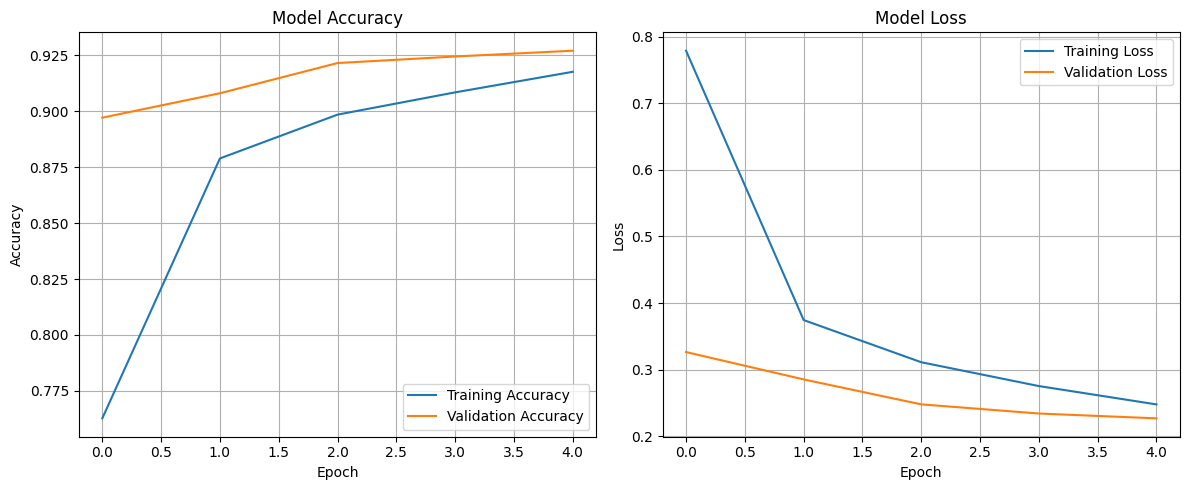

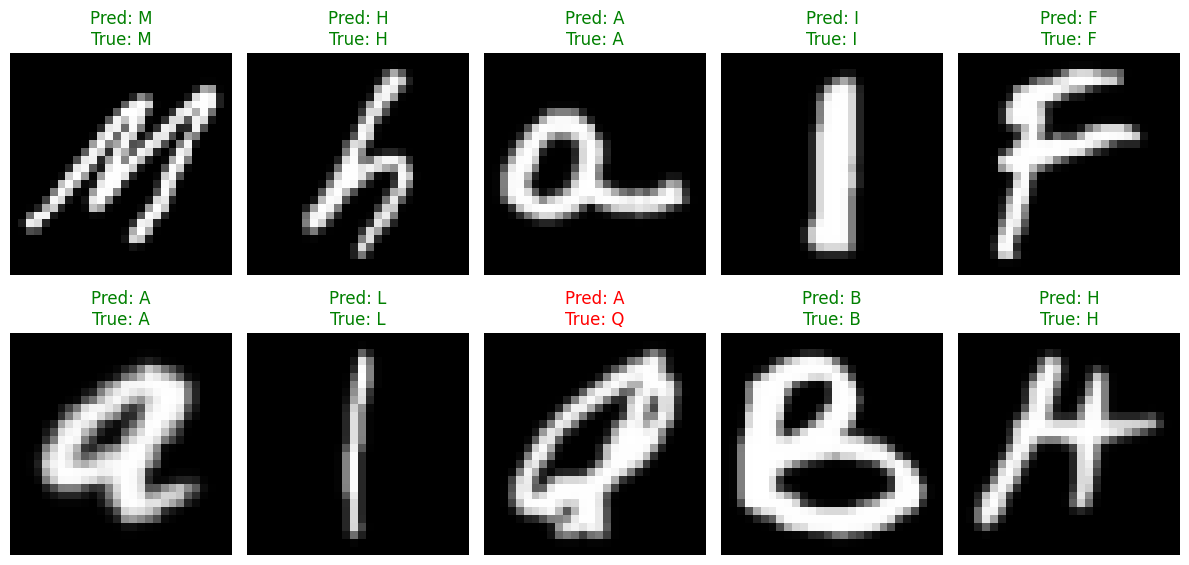

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://15ebb6c907ffb0a543.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [10]:

import tensorflow as tf
import tensorflow_datasets as tfds
import numpy as np
import matplotlib.pyplot as plt
import gradio as gr
from PIL import Image, ImageOps
import string

# 1. Load the EMNIST Letters dataset
print("Loading EMNIST Letters dataset...")

train_raw, val_raw, test_raw = tfds.load(
    "emnist/letters",
    split=["train[:90%]", "train[90%:]", "test"],
    as_supervised=True,
    shuffle_files=False
)

class_names = list(string.ascii_uppercase)

# 2. Preprocess the dataset
def valid_label(image, label):
    return (label >= 1) & (label <= 26)

def preprocess_data(image, label):
    image = tf.transpose(image, perm=[1, 0, 2])
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.cast(label, tf.int32) - 1
    return image, label

def make_dataset(dataset, training=False):
    dataset = dataset.filter(valid_label)

    dataset = dataset.map(
        preprocess_data,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(5000)

    dataset = dataset.batch(128)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = make_dataset(train_raw, True)
val_ds = make_dataset(val_raw)
test_ds = make_dataset(test_raw)

print("Dataset loaded successfully!")

# 3. Build the CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(26, activation="softmax")
])

# 4. Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# 5. Train the model
print("Starting model training...")

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

# 6. Evaluate the model
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# 7. Display training graphs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)
plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(
    history.history["loss"],
    label="Training Loss"
)
plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# 8. Test predictions
for images, labels in test_ds.take(1):

    sample_images = images[:10]
    sample_labels = labels[:10]

    predictions = model.predict(
        sample_images,
        verbose=0
    )

    plt.figure(figsize=(12, 6))

    for i in range(10):
        predicted_index = int(np.argmax(predictions[i]))
        actual_index = int(sample_labels[i].numpy())

        predicted_letter = class_names[predicted_index]
        actual_letter = class_names[actual_index]

        plt.subplot(2, 5, i + 1)

        plt.imshow(
            sample_images[i, :, :, 0],
            cmap="gray"
        )

        plt.title(
            f"Pred: {predicted_letter}\n"
            f"True: {actual_letter}",
            color="green" if predicted_index == actual_index else "red"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

# 9. Preprocess handwritten images
def preprocess_image(editor_value):

    if editor_value is None:
        return None, None

    if isinstance(editor_value, dict):
        image = editor_value.get("composite")
    else:
        image = editor_value

    if image is None:
        return None, None

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.asarray(image))

    # Apply a white background to transparent images
    image = image.convert("RGBA")

    background = Image.new(
        "RGBA",
        image.size,
        (255, 255, 255, 255)
    )

    background.alpha_composite(image)

    # Convert the image to grayscale
    gray = ImageOps.grayscale(
        background.convert("RGB")
    )

    pixels = np.array(gray).astype(np.uint8)

    # Convert dark letters to bright letters
    if np.mean(pixels) > 127:
        pixels = 255 - pixels

    # Remove background noise
    pixels[pixels < 40] = 0

    mask = pixels > 0

    if not np.any(mask):
        return None, None

    # Crop the letter
    ys, xs = np.where(mask)

    cropped = pixels[
        ys.min():ys.max() + 1,
        xs.min():xs.max() + 1
    ]

    letter = Image.fromarray(cropped)

    # Resize while preserving the aspect ratio
    letter.thumbnail(
        (20, 20),
        Image.Resampling.LANCZOS
    )

    # Center the letter
    canvas = Image.new(
        "L",
        (28, 28),
        0
    )

    x = (28 - letter.width) // 2
    y = (28 - letter.height) // 2

    canvas.paste(letter, (x, y))

    # Normalize pixel values
    image_array = np.array(
        canvas,
        dtype=np.float32
    ) / 255.0

    image_array = image_array.reshape(
        1, 28, 28, 1
    )

    # Generate the processed image preview
    preview = canvas.resize(
        (280, 280),
        Image.Resampling.NEAREST
    )

    return image_array, preview

# 10. Predict a handwritten letter
def predict_letter(editor_value):

    processed, preview = preprocess_image(
        editor_value
    )

    if processed is None:
        return {}, None, "Please draw or upload a letter."

    prediction = model.predict(
        processed,
        verbose=0
    )[0]

    probabilities = {
        class_names[i]: float(prediction[i])
        for i in range(26)
    }

    predicted_index = int(np.argmax(prediction))

    predicted_letter = class_names[predicted_index]
    confidence = float(prediction[predicted_index]) * 100

    result_text = (
        f"Predicted Letter: {predicted_letter}\n"
        f"Confidence: {confidence:.2f}%"
    )

    return probabilities, preview, result_text

# 11. Create the drawing canvas
def create_canvas():
    return Image.new(
        "RGB",
        (280, 280),
        "white"
    )

# 12. Create the Gradio interface
with gr.Blocks(title="Alphabet Recognition AI") as demo:

    gr.Markdown(
        "# AI Handwritten Alphabet Recognition"
    )

    gr.Markdown(
        "Draw a letter from A to Z or upload an image. "
        "The AI will identify the handwritten letter."
    )

    with gr.Row():

        input_image = gr.ImageEditor(
            value=create_canvas(),
            type="pil",
            label="Draw or Upload a Letter",
            canvas_size=(280, 280),
            image_mode="RGBA",
            brush=gr.Brush(
                default_size=14,
                colors=["#000000"],
                color_mode="fixed"
            )
        )

        with gr.Column():

            output_label = gr.Label(
                num_top_classes=5,
                label="Prediction Probabilities"
            )

            output_text = gr.Textbox(
                label="Prediction Result",
                lines=2
            )

    processed_output = gr.Image(
        label="Processed 28x28 Image"
    )

    with gr.Row():

        predict_button = gr.Button(
            "Recognize Letter",
            variant="primary"
        )

        clear_button = gr.Button(
            "Clear Canvas"
        )

    # Run letter recognition
    predict_button.click(
        fn=predict_letter,
        inputs=input_image,
        outputs=[
            output_label,
            processed_output,
            output_text
        ]
    )

    # Reset the drawing canvas
    def reset_canvas():
        return create_canvas(), {}, None, ""

    clear_button.click(
        fn=reset_canvas,
        outputs=[
            input_image,
            output_label,
            processed_output,
            output_text
        ]
    )

    gr.Markdown(
        "Draw one letter at a time using a dark pen "
        "on a light background."
    )

    gr.Markdown(
        "This model recognizes 26 alphabet classes. "
        "Uppercase and lowercase letters are treated "
        "as the same class."
    )

# 13. Launch the application
demo.launch()
